In [ ]:
!pip install numpy matplotlib tqdm

In [2]:
# Instalación de librerías necesarias (descomentar si ejecuta en Google Colab o entorno nuevo)
# !pip install numpy matplotlib tqdm

import random
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Fijar semilla aleatoria para garantizar la reproducibilidad de los resultados en el laboratorio
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ Entorno configurado correctamente. Semilla fijada en SEED =", SEED)

✅ Entorno configurado correctamente. Semilla fijada en SEED = 42


In [3]:
# Configuración del espacio de búsqueda y parámetros globales
ALFABETO = "ABCDEFGHIJKLMNÑOPQRSTUVWXYZ0123456789 "
FRASE_OBJETIVO = "IA EVOLUTIVA 2026"
LONGITUD_FRASE = len(FRASE_OBJETIVO)
TAMANO_ALFABETO = len(ALFABETO)

espacio_estados = TAMANO_ALFABETO ** LONGITUD_FRASE
print(f"🎯 Frase Objetivo    : '{FRASE_OBJETIVO}'")
print(f"📏 Longitud (N)      : {LONGITUD_FRASE} caracteres")
print(f"🔤 Tamaño Alfabeto   : {TAMANO_ALFABETO} caracteres")
print(f"🌌 Espacio de Estados: {espacio_estados:.2e} combinaciones posibles")


🎯 Frase Objetivo    : 'IA EVOLUTIVA 2026'
📏 Longitud (N)      : 17 caracteres
🔤 Tamaño Alfabeto   : 38 caracteres
🌌 Espacio de Estados: 7.18e+26 combinaciones posibles


In [4]:
def crear_individuo(longitud):
    """Genera una cadena aleatoria de longitud N basada en el alfabeto."""
    return ''.join(random.choice(ALFABETO) for _ in range(longitud))

def crear_poblacion(tamano, longitud):
    """Crea una lista de 'tamano' individuos aleatorios."""
    return [crear_individuo(longitud) for _ in range(tamano)]

# Prueba de generación
poblacion_inicial_ejemplo = crear_poblacion(5, LONGITUD_FRASE)
print("Muestra de población inicial aleatoria:")
for i, ind in enumerate(poblacion_inicial_ejemplo, 1):
    print(f"  Individuo {i}: '{ind}'")


Muestra de población inicial aleatoria:
  Individuo 1: 'HBQOÑIG7F 0CBFNÑ5'
  Individuo 2: 'B8M7ZÑ1 QAK0UQJNU'
  Individuo 3: 'GFXGVVPC27HXF8RW9'
  Individuo 4: 'MECÑRFÑGXQ2WKWVNQ'
  Individuo 5: 'EK7OK2XQ8ÑTDÑCTYQ'


In [5]:
def evaluar_fitness(individuo, objetivo):
    """Calcula el número de caracteres que coinciden exactamente con el objetivo."""
    return sum(1 for a, b in zip(individuo, objetivo) if a == b)

# Prueba de evaluación
ejemplo_ind = "IA EVOLUXIVA 2020"
fit_val = evaluar_fitness(ejemplo_ind, FRASE_OBJETIVO)
print(f"Evaluación del individuo '{ejemplo_ind}': {fit_val}/{LONGITUD_FRASE} aciertos.")


Evaluación del individuo 'IA EVOLUXIVA 2020': 15/17 aciertos.


In [6]:
def seleccion_torneo(poblacion, fitnesses, k=3):
    """Selecciona al mejor individuo de un subconjunto aleatorio de tamaño k."""
    seleccionados_indices = random.sample(range(len(poblacion)), k)
    mejor_idx = max(seleccionados_indices, key=lambda idx: fitnesses[idx])
    return poblacion[mejor_idx]


In [7]:
def cruce_un_punto(padre1, padre2, prob_cruce=0.85):
    """Combina dos padres en un punto de corte aleatorio con probabilidad prob_cruce."""
    if random.random() < prob_cruce:
        punto_corte = random.randint(1, len(padre1) - 1)
        hijo1 = padre1[:punto_corte] + padre2[punto_corte:]
        hijo2 = padre2[:punto_corte] + padre1[punto_corte:]
        return hijo1, hijo2
    return padre1, padre2

# Prueba de cruce
p1, p2 = "AAAAAFFFFFF2026", "IA EVOLUTIVABBBB"
h1, h2 = cruce_un_punto(p1, p2, prob_cruce=1.0)
print(f"""Padre 1: '{p1}' \n
Padre 2: '{p2}'\n
Hijo 1 : '{h1}'\n
Hijo 2 : '{h2}'""")


Padre 1: 'AAAAAFFFFFF2026' 

Padre 2: 'IA EVOLUTIVABBBB'

Hijo 1 : 'AAAAAFFFFFVABBBB'

Hijo 2 : 'IA EVOLUTIF2026'


In [8]:
def mutacion(individuo, prob_mutacion=0.01):
    """Altera aleatoriamente caracteres individuales con probabilidad prob_mutacion."""
    resultado = []
    for char in individuo:
        if random.random() < prob_mutacion:
            resultado.append(random.choice(ALFABETO))
        else:
            resultado.append(char)
    return ''.join(resultado)


In [9]:
def algoritmo_genetico(objetivo, tam_poblacion=150, max_generaciones=200, 
                       prob_cruce=0.85, prob_mutacion=0.01, k_torneo=3, verbose=True):
    """Ejecuta el ciclo de vida completo del Algoritmo Genético."""
    longitud = len(objetivo)
    poblacion = crear_poblacion(tam_poblacion, longitud)
    
    historial_max = []
    historial_avg = []
    
    for gen in range(1, max_generaciones + 1):
        # 1. Evaluación de la población
        fitnesses = [evaluar_fitness(ind, objetivo) for ind in poblacion]
        
        max_fit = max(fitnesses)
        avg_fit = sum(fitnesses) / tam_poblacion
        mejor_ind = poblacion[fitnesses.index(max_fit)]
        
        historial_max.append(max_fit)
        historial_avg.append(avg_fit)
        
        if verbose and (gen == 1 or gen % 10 == 0 or max_fit == longitud):
            print(f"Gen {gen:03d} | Fit Máx: {max_fit:02d}/{longitud} | Fit Prom: {avg_fit:5.2f} | Mejor: '{mejor_ind}'")
            
        # Criterio de parada: ¿Alcanzó la meta?
        if max_fit == longitud:
            if verbose:
                print(f"🎉 ¡SOLUCIÓN ENCONTRADA EN LA GENERACIÓN {gen}!")
                print(f"Resultados Finales: '{mejor_ind}' (Aptitud: {max_fit}/{longitud})")
            break
            
        # 2. Elitismo: Mantener al mejor individuo sin modificaciones
        nueva_poblacion = [mejor_ind]
        
        # 3. Reproducción hasta completar la nueva población
        while len(nueva_poblacion) < tam_poblacion:
            padre1 = seleccion_torneo(poblacion, fitnesses, k_torneo)
            padre2 = seleccion_torneo(poblacion, fitnesses, k_torneo)
            
            hijo1, hijo2 = cruce_un_punto(padre1, padre2, prob_cruce)
            
            nueva_poblacion.append(mutacion(hijo1, prob_mutacion))
            if len(nueva_poblacion) < tam_poblacion:
                nueva_poblacion.append(mutacion(hijo2, prob_mutacion))
                
        poblacion = nueva_poblacion
        
    return historial_max, historial_avg, mejor_ind

# Ejecución principal
print("🚀 Iniciando la ejecución del Algoritmo Genético...")
hist_max, hist_avg, solucion = algoritmo_genetico(
    objetivo=FRASE_OBJETIVO,
    tam_poblacion=150,
    max_generaciones=200,
    prob_cruce=0.85,
    prob_mutacion=0.01,
    k_torneo=3
)


🚀 Iniciando la ejecución del Algoritmo Genético...
Gen 001 | Fit Máx: 02/17 | Fit Prom:  0.46 | Mejor: '8AHEJ7CW 8J0ICSWC'
Gen 010 | Fit Máx: 08/17 | Fit Prom:  6.37 | Mejor: 'IP 4FFLUWI8D 27Y6'
Gen 020 | Fit Máx: 13/17 | Fit Prom: 12.04 | Mejor: 'IA E55LUWIVA 20S6'
Gen 030 | Fit Máx: 14/17 | Fit Prom: 12.85 | Mejor: 'IA EJLLUWIVA 2026'
Gen 040 | Fit Máx: 15/17 | Fit Prom: 14.87 | Mejor: 'IA EVFLUWIVA 2026'
Gen 050 | Fit Máx: 16/17 | Fit Prom: 14.93 | Mejor: 'IA EVOLUWIVA 2026'
Gen 060 | Fit Máx: 16/17 | Fit Prom: 15.89 | Mejor: 'IA EVOLUWIVA 2026'
Gen 070 | Fit Máx: 16/17 | Fit Prom: 15.86 | Mejor: 'IA EVOLUWIVA 2026'
Gen 080 | Fit Máx: 16/17 | Fit Prom: 15.79 | Mejor: 'IA EVOLUWIVA 2026'
Gen 089 | Fit Máx: 17/17 | Fit Prom: 15.83 | Mejor: 'IA EVOLUTIVA 2026'
🎉 ¡SOLUCIÓN ENCONTRADA EN LA GENERACIÓN 89!
Resultados Finales: 'IA EVOLUTIVA 2026' (Aptitud: 17/17)


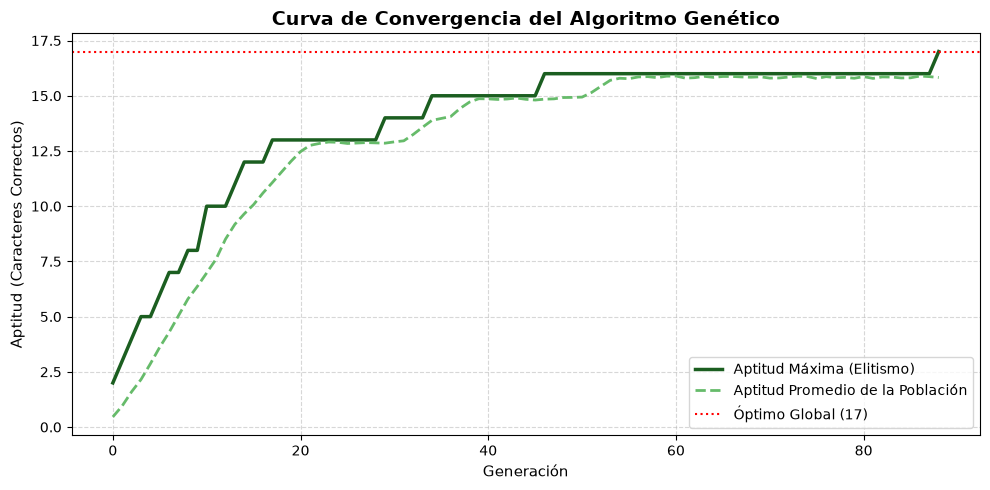

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(hist_max, label="Aptitud Máxima (Elitismo)", color="#1B5E20", linewidth=2.5)
plt.plot(hist_avg, label="Aptitud Promedio de la Población", color="#66BB6A", linestyle="--", linewidth=2)
plt.axhline(y=LONGITUD_FRASE, color="red", linestyle=":", label=f"Óptimo Global ({LONGITUD_FRASE})")

plt.title("Curva de Convergencia del Algoritmo Genético", fontsize=14, fontweight="bold")
plt.xlabel("Generación", fontsize=11)
plt.ylabel("Aptitud (Caracteres Correctos)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


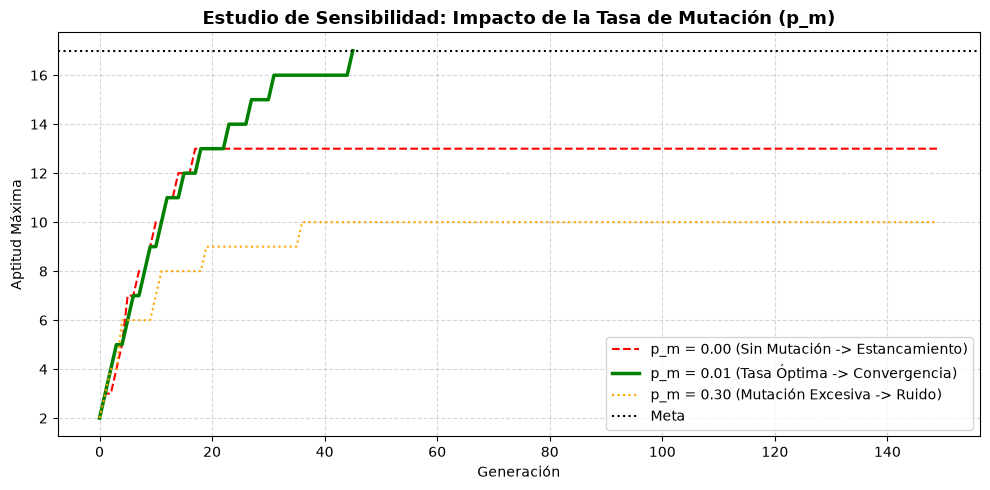

In [11]:
tasas_mutacion = [0.00, 0.01, 0.30]
resultados_exp = {}

for pm in tasas_mutacion:
    random.seed(SEED)
    np.random.seed(SEED)
    h_max, _, _ = algoritmo_genetico(
        objetivo=FRASE_OBJETIVO,
        tam_poblacion=150,
        max_generaciones=150,
        prob_cruce=0.85,
        prob_mutacion=pm,
        verbose=False
    )
    resultados_exp[f"p_m = {pm}"] = h_max

plt.figure(figsize=(10, 5))
plt.plot(resultados_exp["p_m = 0.0"], label="p_m = 0.00 (Sin Mutación -> Estancamiento)", color="red", linestyle="--")
plt.plot(resultados_exp["p_m = 0.01"], label="p_m = 0.01 (Tasa Óptima -> Convergencia)", color="green", linewidth=2.5)
plt.plot(resultados_exp["p_m = 0.3"], label="p_m = 0.30 (Mutación Excesiva -> Ruido)", color="orange", linestyle=":")
plt.axhline(y=LONGITUD_FRASE, color="black", linestyle=":", label="Meta")

plt.title("Estudio de Sensibilidad: Impacto de la Tasa de Mutación (p_m)", fontsize=13, fontweight="bold")
plt.xlabel("Generación")
plt.ylabel("Aptitud Máxima")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()
